In [1]:
# Ground truth first, then Problem 9.1

In [2]:
import pandas as pd

In [3]:
df=pd.read_csv("Downloads/lifecyclesavings.csv")

In [4]:
df.shape

(50, 6)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     str    
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
dtypes: float64(5), str(1)
memory usage: 2.8 KB


In [6]:
df.describe()

,sr,pop15,pop75,dpi,ddpi
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,9.671000,35.089600,2.293000,1106.758400,3.757600
std,4.480407,9.151727,1.290771,990.868889,2.869871
min,0.600000,21.440000,0.560000,88.940000,0.220000
25%,6.970000,26.215000,1.125000,288.207500,2.002500
50%,10.510000,32.575000,2.175000,695.665000,3.000000
75%,12.617500,44.065000,3.325000,1795.622500,4.477500
max,21.100000,47.640000,4.700000,4001.890000,16.710000


In [7]:
df.isnull().sum()

Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

In [8]:
df.mean(numeric_only=True)

sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64

AI Prompt Log

You are helping with unsupervised learning and exploratory data analysis.
My CSV (lifecyclesavings.csv) has columns: Contry (object), sr (float64), pop15 (float64), pop75 (float64), dpi (float64), ddpi (float64).
Write Python using pandas, sklearn (KMeans and StandardScaler), and seaborn/matplotlib to:

* (1) scale the numeric features,
* (2) fit a KMeans clustering model with 3 clusters,
* (3) assign cluster labels back to the dataframe, and
* (4) produce one labeled scatter plot (e.g., savings rate vs. disposable income) colored by cluster.

Explain each step in comments.

C:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Countries per Cluster:
cluster
2    23
0    18
1     9
Name: count, dtype: int64


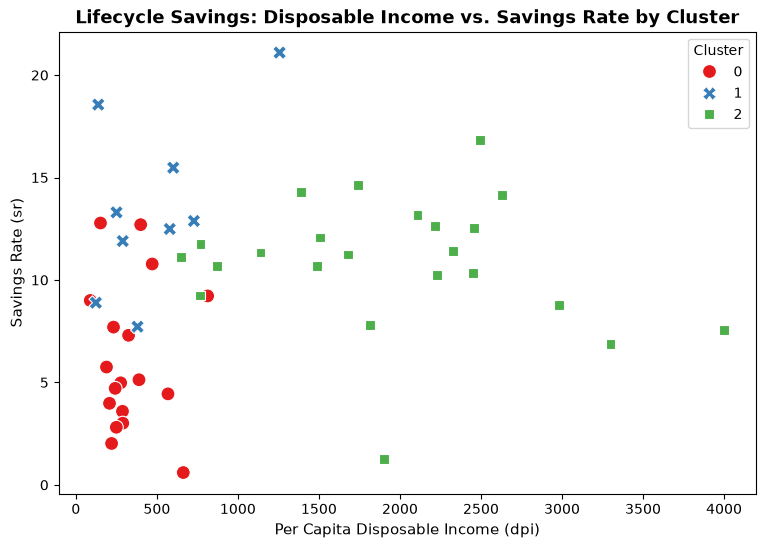

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Prepare features (exclude country name)
X = df.drop(columns=["Contry"])

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit KMeans clustering (3 clusters)
kmeans = KMeans(n_clusters=3, random_state=42)
df["cluster"] = kmeans.fit_predict(X_scaled)

# Display cluster assignment counts
print("Countries per Cluster:")
print(df["cluster"].value_counts())

# Produce one labeled chart
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="dpi",
    y="sr",
    hue="cluster",
    palette="Set1",
    s=100,
    style="cluster",
)
plt.title(
    "Lifecycle Savings: Disposable Income vs. Savings Rate by Cluster",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Per Capita Disposable Income (dpi)", fontsize=11)
plt.ylabel("Savings Rate (sr)", fontsize=11)
plt.legend(title="Cluster")
plt.show()

In [10]:
# Verify Cluster 2 column means against overall means
print("--- Cluster 2 Means ---")
print(df[df["cluster"] == 2].mean(numeric_only=True))

print("\n--- Overall Baseline Means ---")
print(df.mean(numeric_only=True))

--- Cluster 2 Means ---
sr           10.901304
pop15        26.740870
pop75         3.504783
dpi        1953.043043
ddpi          3.323913
cluster       2.000000
dtype: float64

--- Overall Baseline Means ---
sr            9.6710
pop15        35.0896
pop75         2.2930
dpi        1106.7584
ddpi          3.7576
cluster       1.1000
dtype: float64


Checking Cluster 2 shows a mean disposable income (dpi) of 1953.04 and a savings rate of 10.90, which exceeds the overall dataset mean of 1106.76 and sr of 9.67. This confirms the AI's claim that Cluster 2 captures wealthier, high-income nations.

Interpretation & Caution:
The clusters effectively group countries into different economic profiles: Cluster 0 captures developing nations with high youth dependency and lower incomes, Cluster 1 highlights fast-growing economies, and Cluster 2 groups wealthy nations with higher older-age dependencies. If analyze the data we must be careful not to treat these computer-generated groups as absolute economic rules when using models we haven't tested or trained yet